In [ ]:
import pandas as pd
#on va partir sur du pandas (mais on testera polars après)

In [2]:
# del df_accidents
# del df_cat_vehicule
# del df_profil_collision
# del df_profil_conditions
# del df_profil_conducteur
# del df_profil_topographie
# del df_profil_victime
# del df_type_vehicule
# del df_vehicule
# del df_victimes

In [93]:
# on va remplir nos df
#on est parti d'un .bak exporté vers Excel et csv. 
#pas le plus propre mais après quelques vérifications j'ai tout. 

df_accidents = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil2')
df_cat_vehicule = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil3')
df_profil_collision = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil4')
df_profil_conditions = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil5')
df_profil_conducteur = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil6')
df_profil_topographie = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil7')
df_profil_victime = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil8')
df_type_vehicule = pd.read_excel('relational_accidents.xlsx', sheet_name='Feuil10')

df_vehicule = pd.read_csv('tablevehicule.txt', encoding='latin1')
df_victimes = pd.read_csv('tablevictime.txt', encoding='latin1')



In [94]:
#petit check sur les shapes. 
#ça correspond à ma db de base, ok. 
print(df_accidents.shape)
print(df_cat_vehicule.shape)
print(df_profil_collision.shape)
print(df_profil_conditions.shape)
print(df_profil_conducteur.shape)
print(df_profil_topographie.shape)
print(df_profil_victime.shape)
print(df_type_vehicule.shape)
print(df_vehicule.shape)
print(df_victimes.shape)

(839985, 8)
(7, 2)
(29750, 6)
(600, 4)
(30, 3)
(6000, 6)
(52500, 7)
(33, 3)
(1433389, 6)
(1876005, 8)


In [95]:
#petit check sur les shapes. 
#ça correspond à ma db de base, ok. 
print(df_accidents.dtypes)
print(df_cat_vehicule.dtypes)
print(df_profil_collision.dtypes)
print(df_profil_conditions.dtypes)
print(df_profil_conducteur.dtypes)
print(df_profil_topographie.dtypes)
print(df_profil_victime.dtypes)
print(df_type_vehicule.dtypes)
print(df_vehicule.dtypes)
print(df_victimes.dtypes)

N°Accident                    int64
Clé Profil Conditions         int64
Clé Profil Topographique      int64
com                         float64
Dep                           int64
Date                         object
Hour30                        int64
MinuteNumber                  int64
dtype: object
CatID         int64
Catégorie    object
dtype: object
Clé Profil Collision     int64
Obstacle Fixe           object
Obstacle Mobile         object
Choc                    object
Type de Manoeuvre       object
Manoeuvre               object
dtype: object
Clé_Profil_Conditions     int64
Luminosité               object
Cond. atmos              object
Surface                  object
dtype: object
Clé Profil Conducteur     int64
Sexe                     object
Tranche d'âge            object
dtype: object
Clé_Profil_Topographie     int64
Agglomération             object
Intersection              object
Catégorie Route           object
Régime de circulation     object
Profil en long            o

![schema db](db_accidents_schema.jpg)

Schema obtenu sur SSMS
On va commencer par se pencher sur les 3 tables centrales : accident - véhicule - victime. 
A noter que ce sont des one-to-many. Donc que un num d'accident est appelé plusieurs fois dans la table véhicules et que la clé véhicule est appelée plusieurs fois dans la table victime. 
Regardons les null.



In [100]:
#null - accidents
df_accidents.isnull().sum()

N°Accident                  0
Clé Profil Conditions       0
Clé Profil Topographique    0
com                         2
Dep                         0
Date                        0
Hour30                      0
MinuteNumber                0
dtype: int64

2 com vides... on s'en remettra. 


In [101]:
df_vehicule.isnull().sum()

Clé Véhicule                 0
N°Accident                   0
N°Vehicule                   0
Clé Type Véhicule            0
Clé Profil_Conducteur    35694
Clé Profil Collision         0
dtype: int64

Attention. +35k clé conducteurs null. C'est significatif même si ça n'empêchera pas l'analyse. On doit poser la question au métier. (Hypothèse de délit de fuite ?, autre ?)

In [102]:
pd.merge(df_vehicule[df_vehicule['Clé Profil_Conducteur'].isnull()], df_profil_collision, on='Clé Profil Collision').groupby('Obstacle Fixe').count()

,Clé Véhicule,N°Accident,N°Vehicule,Clé Type Véhicule,Clé Profil_Conducteur,Clé Profil Collision,Obstacle Mobile,Choc,Type de Manoeuvre,Manoeuvre
Obstacle Fixe,,,,,,,,,,
Arbre,84,84,84,84,0,84,84,84,84,84
Autre glissière,16,16,16,16,0,16,16,16,16,16
Autre obstacle fixe sur chaussée,146,146,146,146,0,146,146,146,146,146
Autre obstacle fixe sur trottoir ou accotement,100,100,100,100,0,100,100,100,100,100
Bordure de trottoir,73,73,73,73,0,73,73,73,73,73
"Bâtiment, mur, pile de pont",123,123,123,123,0,123,123,123,123,123
"Fossé, talus, paroi rocheuse",72,72,72,72,0,72,72,72,72,72
Glissière béton,97,97,97,97,0,97,97,97,97,97
Glissière métallique,84,84,84,84,0,84,84,84,84,84


On maintient la question au métier sur les 35k de clés conducteur absentes de la table véhicule. 
On continue sur victime. 

In [103]:
#Regardons les null - victimes
df_victimes.isnull().sum()

Id                       0
Num_Acc                  0
Clé Véhicule            22
Clé_Profil_Victime       0
Majeur ou Mineur      2351
Age                   2351
Type Eq. Sécurité        0
Util. Eq. Sécurité       0
dtype: int64

Il nous manque l'âge des victimes dans 2351 cas. On s'en remettra mais on le note dans notre rapport. 
On n'a pas de clef véhicule dans 22 cas. Regardons ça.


In [77]:
df_victimes[df_victimes['Clé Véhicule'].isnull()]

,Id,Num_Acc,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident
771335,771336,200800075490,NaN,111351,Majeur,29.0,Ceinture,Oui,200800075490
771336,771337,200800075490,NaN,121551,Majeur,47.0,Ceinture,Oui,200800075490
771337,771338,200800075490,NaN,111351,Majeur,26.0,Ceinture,Oui,200800075490
941987,941988,200700082289,NaN,121691,Majeur,52.0,Ceinture,Non déterminable,200700082289
982935,982936,200700083469,NaN,224308,Majeur,22.0,Ceinture,Non déterminable,200700083469
982936,982937,200700083469,NaN,224508,Majeur,47.0,Ceinture,Non déterminable,200700083469
982937,982938,200700083469,NaN,214608,Majeur,53.0,Ceinture,Non déterminable,200700083469
982938,982939,200700083469,NaN,214508,Majeur,41.0,Ceinture,Non déterminable,200700083469
982939,982940,200700083469,NaN,214308,Majeur,20.0,Ceinture,Non déterminable,200700083469
982940,982941,200700083469,NaN,214108,Mineur,8.0,Ceinture,Non déterminable,200700083469


In [110]:
pd.merge(pd.merge(df_victimes[df_victimes['Clé Véhicule'].isnull()], df_accidents, left_on='Num_Acc', right_on='N°Accident', how='left'), df_profil_victime, left_on='Clé_Profil_Victime', right_on='Clé_Profil_victime', how='left')

,Id,Num_Acc,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,Clé Profil Conditions,...,Date,Hour30,MinuteNumber,Clé_Profil_victime,Catégorie,Sexe,Gravité,Tranche d'âge,Motif Déplacement,Place
0,771336,200800075490,NaN,111351,Majeur,29.0,Ceinture,Oui,200800075490,111,...,2008-03-02,14,37,111351,Conducteur,Homme,Indemne,20-29 ans,Promenade – loisirs,Conducteur
1,771337,200800075490,NaN,121551,Majeur,47.0,Ceinture,Oui,200800075490,111,...,2008-03-02,14,37,121551,Conducteur,Femme,Indemne,40-49 ans,Promenade – loisirs,Conducteur
2,771338,200800075490,NaN,111351,Majeur,26.0,Ceinture,Oui,200800075490,111,...,2008-03-02,14,37,111351,Conducteur,Homme,Indemne,20-29 ans,Promenade – loisirs,Conducteur
3,941988,200700082289,NaN,121691,Majeur,52.0,Ceinture,Non déterminable,200700082289,111,...,2007-04-14,11,40,121691,Conducteur,Femme,Indemne,50-59 ans,Autre,Conducteur
4,982936,200700083469,NaN,224308,Majeur,22.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,224308,Passager,Femme,Blessé léger,20-29 ans,NC,Passager Milieu Central
5,982937,200700083469,NaN,224508,Majeur,47.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,224508,Passager,Femme,Blessé léger,40-49 ans,NC,Passager Milieu Central
6,982938,200700083469,NaN,214608,Majeur,53.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,214608,Passager,Homme,Blessé léger,50-59 ans,NC,Passager Milieu Central
7,982939,200700083469,NaN,214508,Majeur,41.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,214508,Passager,Homme,Blessé léger,40-49 ans,NC,Passager Milieu Central
8,982940,200700083469,NaN,214308,Majeur,20.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,214308,Passager,Homme,Blessé léger,20-29 ans,NC,Passager Milieu Central
9,982941,200700083469,NaN,214108,Mineur,8.0,Ceinture,Non déterminable,200700083469,182,...,2007-08-12,9,40,214108,Passager,Homme,Blessé léger,0-9 ans,NC,Passager Milieu Central


Difficile de dégager de l'homogénéité de ces 22. On va les garder, mais on fera une jointure sur Num_Acc pour ces 22 cas là pour garder leur info dans le dataset. 

On va faire des jointures successives pour rappatrier toutes les infos dans une table avec la granulométrie la plus fine : victimes. 

In [ ]:
#del df_vic_veh

In [112]:
# Étape 1 : vic et veh
df_vic_veh = pd.merge(df_victimes, df_vehicule, on='Clé Véhicule', how='left')



In [116]:
df_vic_veh.shape

(1876005, 13)

In [ ]:
# Étape 2 : joindre les accidents

df_vic_veh_acc = pd.merge(df_vic_veh, df_accidents, left_on='N°Accident', right_on='N°Accident', how='left')
#+ les 22 sans Clé véhicule
df

In [128]:
del df_vic_veh_acc

In [138]:
df_vic_veh_acc[df_vic_veh_acc['Clé Véhicule'].isnull()]

,Id,Num_Acc,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,N°Vehicule,Clé Type Véhicule,Clé Profil_Conducteur,Clé Profil Collision,Clé Profil Conditions,Clé Profil Topographique,com,Dep,Date,Hour30,MinuteNumber
771335,771336,200800075490,NaN,111351,Majeur,29.0,Ceinture,Oui,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
771336,771337,200800075490,NaN,121551,Majeur,47.0,Ceinture,Oui,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
771337,771338,200800075490,NaN,111351,Majeur,26.0,Ceinture,Oui,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
941987,941988,200700082289,NaN,121691,Majeur,52.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982935,982936,200700083469,NaN,224308,Majeur,22.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982936,982937,200700083469,NaN,224508,Majeur,47.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982937,982938,200700083469,NaN,214608,Majeur,53.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982938,982939,200700083469,NaN,214508,Majeur,41.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982939,982940,200700083469,NaN,214308,Majeur,20.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
982940,982941,200700083469,NaN,214108,Mineur,8.0,Ceinture,Non déterminable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [140]:
df_accidents.columns

Index(['N°Accident', 'Clé Profil Conditions', 'Clé Profil Topographique',
       'com', 'Dep', 'Date', 'Hour30', 'MinuteNumber'],
      dtype='object')

In [143]:
colonnes = [
    'Clé Profil Conditions', 'Clé Profil Topographique',
    'com', 'Dep', 'Date', 'Hour30', 'MinuteNumber',
]

# On crée une copie indexée par Num_Acc
df_vic_veh_acc_indexed = df_vic_veh_acc.set_index('Num_Acc')
df_accidents_indexed = df_accidents.set_index('N°Accident')

# On met à jour les colonnes voulues
df_vic_veh_acc_indexed.update(df_accidents_indexed[colonnes])

# On remet l’index à plat
df_vic_veh_acc = df_vic_veh_acc_indexed.reset_index()

In [146]:
df_vic_veh_acc

,Num_Acc,Id,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,N°Vehicule,Clé Type Véhicule,Clé Profil_Conducteur,Clé Profil Collision,Clé Profil Conditions,Clé Profil Topographique,com,Dep,Date,Hour30,MinuteNumber
0,201500000809,1,201500000809B02,114351,Majeur,21.0,Casque,Oui,2.015000e+11,B02,2.0,13.0,132315.0,111.0,12321.0,174.0,270.0,2015-06-07,20.0,30.0
1,201500000809,2,201500000809B02,213352,Majeur,25.0,Casque,Non,2.015000e+11,B02,2.0,13.0,132315.0,111.0,12321.0,174.0,270.0,2015-06-07,20.0,30.0
2,201500000809,3,201500000809A01,111301,Majeur,24.0,Ceinture,Oui,2.015000e+11,A01,7.0,13.0,2117.0,111.0,12321.0,174.0,270.0,2015-06-07,20.0,30.0
3,201500000810,4,201500000810B02,114351,Majeur,25.0,Casque,Oui,2.015000e+11,B02,2.0,13.0,2117.0,111.0,11321.0,467.0,270.0,2015-06-30,12.0,45.0
4,201500000810,5,201500000810A01,111551,Majeur,42.0,Ceinture,Oui,2.015000e+11,A01,7.0,15.0,2315.0,111.0,11321.0,467.0,270.0,2015-06-30,12.0,45.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1876000,200500087953,1876001,200500087953A01,114251,Mineur,15.0,Casque,Non déterminable,2.005001e+11,A01,2.0,12.0,2117.0,121.0,23421.0,416.0,974.0,2005-12-27,15.0,0.0
1876001,200500087954,1876002,200500087954A01,114601,Majeur,54.0,Ceinture,Non déterminable,2.005001e+11,A01,7.0,16.0,40001.0,522.0,21231.0,414.0,974.0,2005-12-31,21.0,0.0
1876002,200500087954,1876003,200500087954A01,224602,Majeur,59.0,Ceinture,Non déterminable,2.005001e+11,A01,7.0,16.0,40001.0,522.0,21231.0,414.0,974.0,2005-12-31,21.0,0.0
1876003,200500086196,1876004,NaN,323510,Majeur,44.0,NC,NC,NaN,NaN,NaN,NaN,NaN,111.0,12421.0,125.0,971.0,2005-08-12,13.0,30.0


In [147]:
df_vic_veh_acc['Clé_Profil_Conditions'] = df_vic_veh_acc['Clé Profil Conditions']
df_vic_veh_acc_cond = pd.merge(df_vic_veh_acc, df_profil_conditions, left_on='Clé Profil Conditions', right_on='Clé_Profil_Conditions', how='left')
df_vic_veh_acc_cond.shape

(1876005, 25)

In [150]:
df_vic_veh_acc_cond.columns

Index(['Num_Acc', 'Id', 'Clé Véhicule', 'Clé_Profil_Victime',
       'Majeur ou Mineur', 'Age', 'Type Eq. Sécurité', 'Util. Eq. Sécurité',
       'N°Accident', 'N°Vehicule', 'Clé Type Véhicule',
       'Clé Profil_Conducteur', 'Clé Profil Collision',
       'Clé Profil Conditions', 'Clé Profil Topographique', 'com', 'Dep',
       'Date', 'Hour30', 'MinuteNumber', 'Clé_Profil_Conditions_x',
       'Clé_Profil_Conditions_y', 'Luminosité', 'Cond. atmos', 'Surface'],
      dtype='object')

In [151]:

df_vic_veh_acc_cond_topo = pd.merge(df_vic_veh_acc_cond, df_profil_topographie, left_on='Clé Profil Topographique', right_on='Clé_Profil_Topographie', how='left')
df_vic_veh_acc_cond_topo.shape

(1876005, 31)

In [157]:

df_vic_veh_acc_cond_topo_conduct = pd.merge(df_vic_veh_acc_cond_topo, df_profil_conducteur, left_on='Clé Profil_Conducteur', right_on='Clé Profil Conducteur', how='left')
df_vic_veh_acc_cond_topo_conduct.shape

(1876005, 34)

In [158]:
df_vic_veh_acc_cond_topo_conduct_coll = pd.merge(df_vic_veh_acc_cond_topo_conduct, df_profil_collision, on ='Clé Profil Collision', how='left')
df_vic_veh_acc_cond_topo_conduct_coll.shape

(1876005, 39)

In [ ]:
df_vic_veh_acc_cond_topo_conduct_coll.columns

Index(['Num_Acc', 'Id', 'Clé Véhicule', 'Clé_Profil_Victime',
       'Majeur ou Mineur', 'Age', 'Type Eq. Sécurité', 'Util. Eq. Sécurité',
       'N°Accident', 'N°Vehicule', 'Clé Type Véhicule',
       'Clé Profil_Conducteur', 'Clé Profil Collision',
       'Clé Profil Conditions', 'Clé Profil Topographique', 'com', 'Dep',
       'Date', 'Hour30', 'MinuteNumber', 'Clé_Profil_Conditions_x',
       'Clé_Profil_Conditions_y', 'Luminosité', 'Cond. atmos', 'Surface',
       'Clé_Profil_Topographie', 'Agglomération', 'Intersection',
       'Catégorie Route', 'Régime de circulation', 'Profil en long',
       'Clé Profil Conducteur', 'Sexe', 'Tranche d'âge', 'Obstacle Fixe',
       'Obstacle Mobile', 'Choc', 'Type de Manoeuvre', 'Manoeuvre'],
      dtype='object')

In [ ]:

df_vic_veh_acc_cond_topo_conduct_coll_typeveh = pd.merge(df_vic_veh_acc_cond_topo_conduct_coll, df_type_vehicule, left_on='Clé Type Véhicule', right_on='ID', how='left')
df_vic_veh_acc_cond_topo_conduct_coll_typeveh.shape

(1876005, 42)

In [161]:
df_vic_veh_acc_cond_topo_conduct_coll_typeveh = pd.merge(df_vic_veh_acc_cond_topo_conduct_coll, df_type_vehicule, left_on='Clé Type Véhicule', right_on='ID', how='left')
df_vic_veh_acc_cond_topo_conduct_coll_typeveh.shape

(1876005, 42)

In [162]:
df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh = pd.merge(df_vic_veh_acc_cond_topo_conduct_coll_typeveh, df_cat_vehicule, on='CatID', how='left')
df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh.shape

(1876005, 43)

In [163]:
df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh.columns

Index(['Num_Acc', 'Id', 'Clé Véhicule', 'Clé_Profil_Victime',
       'Majeur ou Mineur', 'Age', 'Type Eq. Sécurité', 'Util. Eq. Sécurité',
       'N°Accident', 'N°Vehicule', 'Clé Type Véhicule',
       'Clé Profil_Conducteur', 'Clé Profil Collision',
       'Clé Profil Conditions', 'Clé Profil Topographique', 'com', 'Dep',
       'Date', 'Hour30', 'MinuteNumber', 'Clé_Profil_Conditions_x',
       'Clé_Profil_Conditions_y', 'Luminosité', 'Cond. atmos', 'Surface',
       'Clé_Profil_Topographie', 'Agglomération', 'Intersection',
       'Catégorie Route', 'Régime de circulation', 'Profil en long',
       'Clé Profil Conducteur', 'Sexe', 'Tranche d'âge', 'Obstacle Fixe',
       'Obstacle Mobile', 'Choc', 'Type de Manoeuvre', 'Manoeuvre', 'ID',
       'Véhicule', 'CatID', 'Catégorie'],
      dtype='object')

In [166]:

df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh_provic = pd.merge(df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh, df_profil_victime, left_on='Clé_Profil_Victime',right_on='Clé_Profil_victime', how='left') 
df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh_provic.shape

(1876005, 50)

In [167]:
df_full = df_vic_veh_acc_cond_topo_conduct_coll_typeveh_catveh_provic.copy()

In [ ]:
df_full
#attention aux colonnes qui ont le même nom :-p

,Num_Acc,Id,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,N°Vehicule,...,Véhicule,CatID,Catégorie_x,Clé_Profil_victime,Catégorie_y,Sexe_y,Gravité,Tranche d'âge_y,Motif Déplacement,Place
0,201500000809,1,201500000809B02,114351,Majeur,21.0,Casque,Oui,2.015000e+11,B02,...,Cyclomoteur <50cm3,1.0,2-Roues,114351,Conducteur,Homme,Blessé léger,20-29 ans,Promenade – loisirs,Conducteur
1,201500000809,2,201500000809B02,213352,Majeur,25.0,Casque,Non,2.015000e+11,B02,...,Cyclomoteur <50cm3,1.0,2-Roues,213352,Passager,Homme,Blessé hospitalisé,20-29 ans,Promenade – loisirs,Passager Avant Droit
2,201500000809,3,201500000809A01,111301,Majeur,24.0,Ceinture,Oui,2.015000e+11,A01,...,Véhicule Léger seul,7.0,Voiture,111301,Conducteur,Homme,Indemne,20-29 ans,NC,Conducteur
3,201500000810,4,201500000810B02,114351,Majeur,25.0,Casque,Oui,2.015000e+11,B02,...,Cyclomoteur <50cm3,1.0,2-Roues,114351,Conducteur,Homme,Blessé léger,20-29 ans,Promenade – loisirs,Conducteur
4,201500000810,5,201500000810A01,111551,Majeur,42.0,Ceinture,Oui,2.015000e+11,A01,...,Véhicule Léger seul,7.0,Voiture,111551,Conducteur,Homme,Indemne,40-49 ans,Promenade – loisirs,Conducteur
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1876000,200500087953,1876001,200500087953A01,114251,Mineur,15.0,Casque,Non déterminable,2.005001e+11,A01,...,Cyclomoteur <50cm3,1.0,2-Roues,114251,Conducteur,Homme,Blessé léger,10-19 ans,Promenade – loisirs,Conducteur
1876001,200500087954,1876002,200500087954A01,114601,Majeur,54.0,Ceinture,Non déterminable,2.005001e+11,A01,...,Véhicule Léger seul,7.0,Voiture,114601,Conducteur,Homme,Blessé léger,50-59 ans,NC,Conducteur
1876002,200500087954,1876003,200500087954A01,224602,Majeur,59.0,Ceinture,Non déterminable,2.005001e+11,A01,...,Véhicule Léger seul,7.0,Voiture,224602,Passager,Femme,Blessé léger,50-59 ans,NC,Passager Avant Droit
1876003,200500086196,1876004,NaN,323510,Majeur,44.0,NC,NC,NaN,NaN,...,NaN,NaN,NaN,323510,Piéton,Femme,Blessé hospitalisé,40-49 ans,Domicile – travail,NC


In [169]:
df_full.dtypes

Num_Acc                       int64
Id                            int64
Clé Véhicule                 object
Clé_Profil_Victime            int64
Majeur ou Mineur             object
Age                         float64
Type Eq. Sécurité            object
Util. Eq. Sécurité           object
N°Accident                  float64
N°Vehicule                   object
Clé Type Véhicule           float64
Clé Profil_Conducteur       float64
Clé Profil Collision        float64
Clé Profil Conditions       float64
Clé Profil Topographique    float64
com                         float64
Dep                         float64
Date                         object
Hour30                      float64
MinuteNumber                float64
Clé_Profil_Conditions_x     float64
Clé_Profil_Conditions_y       int64
Luminosité                   object
Cond. atmos                  object
Surface                      object
Clé_Profil_Topographie        int64
Agglomération                object
Intersection                

In [170]:
df_full['Dep'].value_counts()

Dep
750.0    175706
130.0    115876
930.0     75031
920.0     66603
940.0     65354
          ...  
90.0       2948
150.0      2323
480.0      2129
230.0      2052
976.0      1147
Name: count, Length: 101, dtype: int64

In [171]:
data = []
with open("depts2016.txt", encoding="latin1") as f:
    for line in f:
        parts = line.strip().split(maxsplit=5)
        if len(parts) == 6:
            data.append(parts)
        else:
            print("❌ Ligne toujours malformée :", line.strip())

df_dept = pd.DataFrame(data, columns=["REGION", "DEP", "CHEFLIEU", "TNCC", "NCC", "NCCENR"])

In [172]:
df_dept

,REGION,DEP,CHEFLIEU,TNCC,NCC,NCCENR
0,REGION,DEP,CHEFLIEU,TNCC,NCC,NCCENR
1,84,01,01053,5,AIN,Ain
2,32,02,02408,5,AISNE,Aisne
3,84,03,03190,5,ALLIER,Allier
4,93,04,04070,4,ALPES-DE-HAUTE-PROVENCE,Alpes-de-Haute-Provence
...,...,...,...,...,...,...
97,01,971,97105,3,GUADELOUPE,Guadeloupe
98,02,972,97209,3,MARTINIQUE,Martinique
99,03,973,97302,3,GUYANE,Guyane
100,04,974,97411,0,LA,REUNION\tLa Réunion


In [173]:
df_full['Dep_clean'] = df_full['Dep'].astype(str).apply(
    lambda x: x[:-3] if x.endswith('0') else x
)

In [174]:
df_full

,Num_Acc,Id,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,N°Vehicule,...,CatID,Catégorie_x,Clé_Profil_victime,Catégorie_y,Sexe_y,Gravité,Tranche d'âge_y,Motif Déplacement,Place,Dep_clean
0,201500000809,1,201500000809B02,114351,Majeur,21.0,Casque,Oui,2.015000e+11,B02,...,1.0,2-Roues,114351,Conducteur,Homme,Blessé léger,20-29 ans,Promenade – loisirs,Conducteur,27
1,201500000809,2,201500000809B02,213352,Majeur,25.0,Casque,Non,2.015000e+11,B02,...,1.0,2-Roues,213352,Passager,Homme,Blessé hospitalisé,20-29 ans,Promenade – loisirs,Passager Avant Droit,27
2,201500000809,3,201500000809A01,111301,Majeur,24.0,Ceinture,Oui,2.015000e+11,A01,...,7.0,Voiture,111301,Conducteur,Homme,Indemne,20-29 ans,NC,Conducteur,27
3,201500000810,4,201500000810B02,114351,Majeur,25.0,Casque,Oui,2.015000e+11,B02,...,1.0,2-Roues,114351,Conducteur,Homme,Blessé léger,20-29 ans,Promenade – loisirs,Conducteur,27
4,201500000810,5,201500000810A01,111551,Majeur,42.0,Ceinture,Oui,2.015000e+11,A01,...,7.0,Voiture,111551,Conducteur,Homme,Indemne,40-49 ans,Promenade – loisirs,Conducteur,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1876000,200500087953,1876001,200500087953A01,114251,Mineur,15.0,Casque,Non déterminable,2.005001e+11,A01,...,1.0,2-Roues,114251,Conducteur,Homme,Blessé léger,10-19 ans,Promenade – loisirs,Conducteur,97
1876001,200500087954,1876002,200500087954A01,114601,Majeur,54.0,Ceinture,Non déterminable,2.005001e+11,A01,...,7.0,Voiture,114601,Conducteur,Homme,Blessé léger,50-59 ans,NC,Conducteur,97
1876002,200500087954,1876003,200500087954A01,224602,Majeur,59.0,Ceinture,Non déterminable,2.005001e+11,A01,...,7.0,Voiture,224602,Passager,Femme,Blessé léger,50-59 ans,NC,Passager Avant Droit,97
1876003,200500086196,1876004,NaN,323510,Majeur,44.0,NC,NC,NaN,NaN,...,NaN,NaN,323510,Piéton,Femme,Blessé hospitalisé,40-49 ans,Domicile – travail,NC,97


In [175]:
df_full.Dep_clean.value_counts()

Dep_clean
75    175706
13    115876
93     75031
92     66603
94     65354
       ...  
46      3122
9       2948
15      2323
48      2129
23      2052
Name: count, Length: 96, dtype: int64

In [177]:

df_full_avec_dep = pd.merge(df_full, df_dept, left_on='Dep_clean', right_on='DEP', how='left')

In [178]:
df_full_avec_dep.shape

(1876005, 57)

In [179]:
df_full_avec_dep

,Num_Acc,Id,Clé Véhicule,Clé_Profil_Victime,Majeur ou Mineur,Age,Type Eq. Sécurité,Util. Eq. Sécurité,N°Accident,N°Vehicule,...,Tranche d'âge_y,Motif Déplacement,Place,Dep_clean,REGION,DEP,CHEFLIEU,TNCC,NCC,NCCENR
0,201500000809,1,201500000809B02,114351,Majeur,21.0,Casque,Oui,2.015000e+11,B02,...,20-29 ans,Promenade – loisirs,Conducteur,27,28,27,27229,5,EURE,Eure
1,201500000809,2,201500000809B02,213352,Majeur,25.0,Casque,Non,2.015000e+11,B02,...,20-29 ans,Promenade – loisirs,Passager Avant Droit,27,28,27,27229,5,EURE,Eure
2,201500000809,3,201500000809A01,111301,Majeur,24.0,Ceinture,Oui,2.015000e+11,A01,...,20-29 ans,NC,Conducteur,27,28,27,27229,5,EURE,Eure
3,201500000810,4,201500000810B02,114351,Majeur,25.0,Casque,Oui,2.015000e+11,B02,...,20-29 ans,Promenade – loisirs,Conducteur,27,28,27,27229,5,EURE,Eure
4,201500000810,5,201500000810A01,111551,Majeur,42.0,Ceinture,Oui,2.015000e+11,A01,...,40-49 ans,Promenade – loisirs,Conducteur,27,28,27,27229,5,EURE,Eure
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1876000,200500087953,1876001,200500087953A01,114251,Mineur,15.0,Casque,Non déterminable,2.005001e+11,A01,...,10-19 ans,Promenade – loisirs,Conducteur,97,NaN,NaN,NaN,NaN,NaN,NaN
1876001,200500087954,1876002,200500087954A01,114601,Majeur,54.0,Ceinture,Non déterminable,2.005001e+11,A01,...,50-59 ans,NC,Conducteur,97,NaN,NaN,NaN,NaN,NaN,NaN
1876002,200500087954,1876003,200500087954A01,224602,Majeur,59.0,Ceinture,Non déterminable,2.005001e+11,A01,...,50-59 ans,NC,Passager Avant Droit,97,NaN,NaN,NaN,NaN,NaN,NaN
1876003,200500086196,1876004,NaN,323510,Majeur,44.0,NC,NC,NaN,NaN,...,40-49 ans,Domicile – travail,NC,97,NaN,NaN,NaN,NaN,NaN,NaN


In [180]:
df_full_avec_dep.NCC.value_counts()

NCC
PARIS                175706
BOUCHES-DU-RHONE     115876
SEINE-SAINT-DENIS     75031
HAUTS-DE-SEINE        66603
VAL-DE-MARNE          65354
                      ...  
MEUSE                  3729
LOT                    3122
CANTAL                 2323
LOZERE                 2129
CREUSE                 2052
Name: count, Length: 85, dtype: int64

In [181]:
THE_df = df_full_avec_dep

In [182]:
THE_df.shape

(1876005, 57)

In [183]:
THE_df['Date'].dtype

dtype('O')

In [184]:
THE_df['Date'].head(50)

0     2015-06-07
1     2015-06-07
2     2015-06-07
3     2015-06-30
4     2015-06-30
5     2015-08-11
6     2015-08-11
7     2015-08-11
8     2015-08-11
9     2015-08-11
10    2015-09-21
11    2015-09-21
12    2015-10-02
13    2015-10-02
14    2015-11-05
15    2015-11-05
16    2015-11-21
17    2015-11-21
18    2015-11-22
19    2015-11-22
20    2015-11-22
21    2015-11-22
22    2015-11-22
23    2015-11-22
24    2015-11-22
25    2015-12-04
26    2015-12-04
27    2015-09-06
28    2015-09-06
29    2015-09-06
30    2015-09-06
31    2015-09-26
32    2015-09-26
33    2015-09-26
34    2015-09-26
35    2015-11-28
36    2015-11-28
37    2015-07-27
38    2015-07-27
39    2015-11-26
40    2015-11-26
41    2015-06-19
42    2015-06-19
43    2015-02-24
44    2015-02-24
45    2015-05-02
46    2015-05-02
47    2015-06-02
48    2015-06-02
49    2015-06-02
Name: Date, dtype: object

In [189]:
THE_df['Date'].isnull().sum()

np.int64(0)

In [190]:
THE_df['Date_clean'] = pd.to_datetime(THE_df['Date'])

In [185]:
THE_df['Date_clean'] = pd.to_datetime(THE_df['Date'], errors='coerce', dayfirst=True)

In [191]:
THE_df['Date_clean'].isnull().sum()

np.int64(0)

In [192]:
THE_df['Date_clean'].dtype

dtype('<M8[ns]')

In [193]:
THE_df['Date_clean'].value_counts

<bound method IndexOpsMixin.value_counts of 0         2015-06-07
1         2015-06-07
2         2015-06-07
3         2015-06-30
4         2015-06-30
             ...    
1876000   2005-12-27
1876001   2005-12-31
1876002   2005-12-31
1876003   2005-08-12
1876004   2005-11-29
Name: Date_clean, Length: 1876005, dtype: datetime64[ns]>

In [194]:
THE_df['Année'] = THE_df['Date_clean'].dt.year
THE_df['Mois'] = THE_df['Date_clean'].dt.month
THE_df['Jour'] = THE_df['Date_clean'].dt.day
THE_df['Semaine'] = THE_df['Date_clean'].dt.isocalendar().week

In [204]:
THE_df.groupby(['Mois']).size()

Mois
1     143598
2     126313
3     145860
4     150745
5     161984
6     173455
7     169381
8     144052
9     170064
10    176233
11    160543
12    153777
dtype: int64

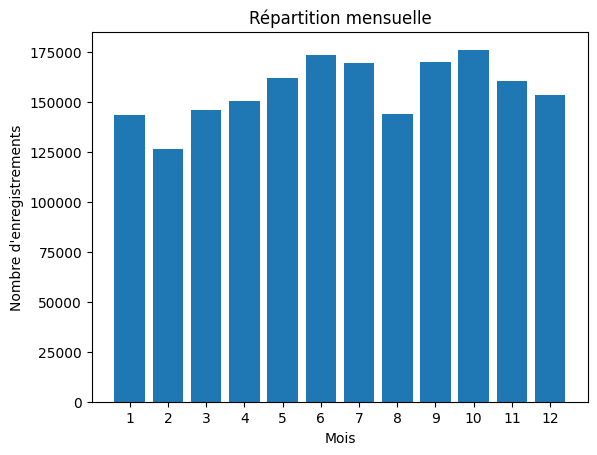

In [205]:
import matplotlib.pyplot as plt

# Comptage par mois et tri croissant (de 1 à 12)
mois_counts = THE_df.groupby(['Mois']).size()

# Affichage
plt.bar(mois_counts.index, mois_counts.values)
plt.xlabel("Mois")
plt.ylabel("Nombre d'enregistrements")
plt.title("Répartition mensuelle")
plt.xticks(range(1, 13))  # Mois de 1 à 12
plt.show()


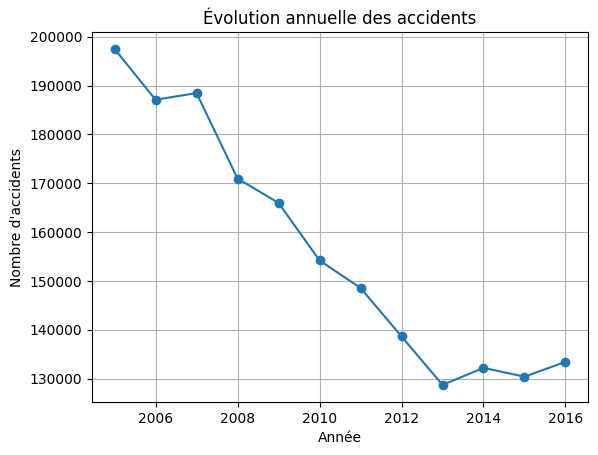

In [206]:
year_counts = THE_df.groupby(THE_df['Année']).size()
year_counts.plot(kind='line', marker='o')
plt.title("Évolution annuelle des accidents")
plt.xlabel("Année")
plt.ylabel("Nombre d'accidents")
plt.grid(True)

Text(0.5, 1.0, 'Accidents par heure du jour')

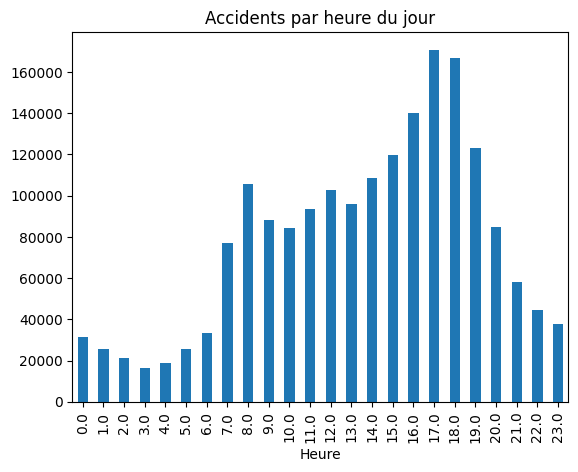

In [207]:
THE_df['Heure'] = THE_df['Hour30']
hour_counts = THE_df['Heure'].value_counts().sort_index()
hour_counts.plot(kind='bar')
plt.title("Accidents par heure du jour")

In [208]:
THE_df.columns

Index(['Num_Acc', 'Id', 'Clé Véhicule', 'Clé_Profil_Victime',
       'Majeur ou Mineur', 'Age', 'Type Eq. Sécurité', 'Util. Eq. Sécurité',
       'N°Accident', 'N°Vehicule', 'Clé Type Véhicule',
       'Clé Profil_Conducteur', 'Clé Profil Collision',
       'Clé Profil Conditions', 'Clé Profil Topographique', 'com', 'Dep',
       'Date', 'Hour30', 'MinuteNumber', 'Clé_Profil_Conditions_x',
       'Clé_Profil_Conditions_y', 'Luminosité', 'Cond. atmos', 'Surface',
       'Clé_Profil_Topographie', 'Agglomération', 'Intersection',
       'Catégorie Route', 'Régime de circulation', 'Profil en long',
       'Clé Profil Conducteur', 'Sexe_x', 'Tranche d'âge_x', 'Obstacle Fixe',
       'Obstacle Mobile', 'Choc', 'Type de Manoeuvre', 'Manoeuvre', 'ID',
       'Véhicule', 'CatID', 'Catégorie_x', 'Clé_Profil_victime', 'Catégorie_y',
       'Sexe_y', 'Gravité', 'Tranche d'âge_y', 'Motif Déplacement', 'Place',
       'Dep_clean', 'REGION', 'DEP', 'CHEFLIEU', 'TNCC', 'NCC', 'NCCENR',
       'Date_cl

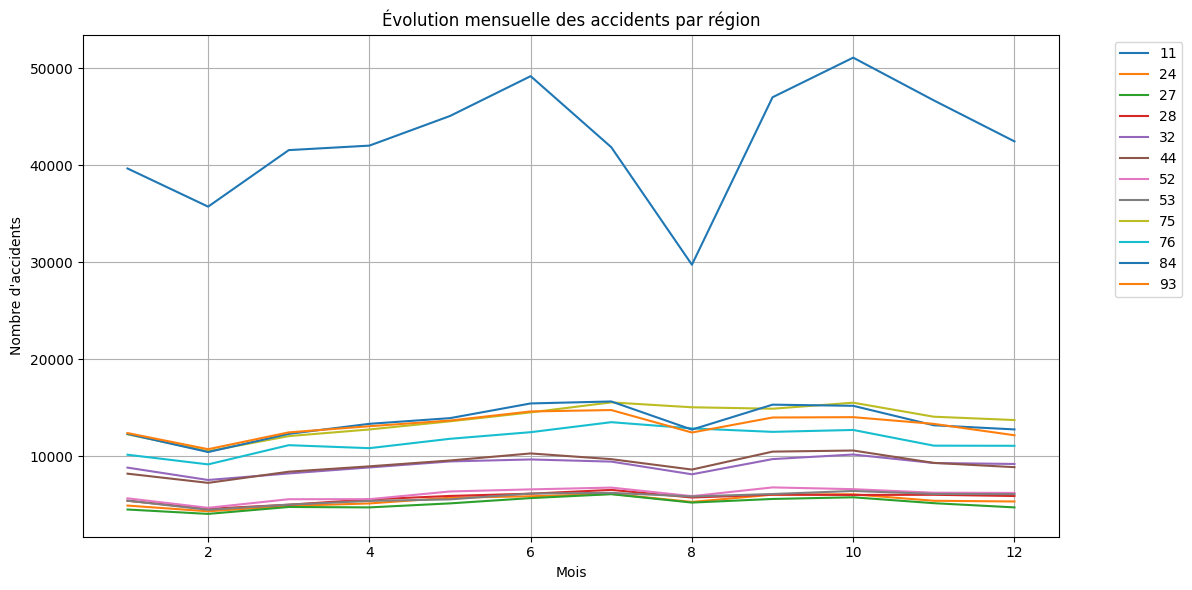

In [209]:
accidents_region_mois = THE_df.groupby(['REGION', 'Mois']).size().unstack(fill_value=0)
accidents_region_mois.T.plot(figsize=(12,6))
plt.title("Évolution mensuelle des accidents par région")
plt.xlabel("Mois")
plt.ylabel("Nombre d'accidents")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [210]:
df_region = pd.read_csv('reg2016.txt', encoding='latin1', sep='\t')

In [211]:
df_region

,REGION,CHEFLIEU,TNCC,NCC,NCCENR
0,1,97105,3,GUADELOUPE,Guadeloupe
1,2,97209,3,MARTINIQUE,Martinique
2,3,97302,3,GUYANE,Guyane
3,4,97411,0,LA REUNION,La Réunion
4,6,97608,0,MAYOTTE,Mayotte
5,11,75056,1,ILE-DE-FRANCE,Île-de-France
6,24,45234,2,CENTRE-VAL DE LOIRE,Centre-Val de Loire
7,27,21231,0,BOURGOGNE-FRANCHE-COMTE,Bourgogne-Franche-Comté
8,28,76540,0,NORMANDIE,Normandie
9,32,59350,2,NORD-PAS-DE-CALAIS-PICARDIE,Nord-Pas-de-Calais-Picardie


In [212]:
THE_df['REGION'].dtype

dtype('O')

In [213]:
df_region['REGION'].dtype

dtype('int64')

In [214]:
THE_df['REGION'] = pd.to_numeric(THE_df['REGION'], errors='coerce').astype('Int64')

In [215]:
THE_def = pd.merge(THE_df, df_region, on='REGION', how='left')

In [216]:
THE_def.shape

(1876005, 67)

In [217]:
THE_def.columns

Index(['Num_Acc', 'Id', 'Clé Véhicule', 'Clé_Profil_Victime',
       'Majeur ou Mineur', 'Age', 'Type Eq. Sécurité', 'Util. Eq. Sécurité',
       'N°Accident', 'N°Vehicule', 'Clé Type Véhicule',
       'Clé Profil_Conducteur', 'Clé Profil Collision',
       'Clé Profil Conditions', 'Clé Profil Topographique', 'com', 'Dep',
       'Date', 'Hour30', 'MinuteNumber', 'Clé_Profil_Conditions_x',
       'Clé_Profil_Conditions_y', 'Luminosité', 'Cond. atmos', 'Surface',
       'Clé_Profil_Topographie', 'Agglomération', 'Intersection',
       'Catégorie Route', 'Régime de circulation', 'Profil en long',
       'Clé Profil Conducteur', 'Sexe_x', 'Tranche d'âge_x', 'Obstacle Fixe',
       'Obstacle Mobile', 'Choc', 'Type de Manoeuvre', 'Manoeuvre', 'ID',
       'Véhicule', 'CatID', 'Catégorie_x', 'Clé_Profil_victime', 'Catégorie_y',
       'Sexe_y', 'Gravité', 'Tranche d'âge_y', 'Motif Déplacement', 'Place',
       'Dep_clean', 'REGION', 'DEP', 'CHEFLIEU_x', 'TNCC_x', 'NCC_x',
       'NCCENR_x', 

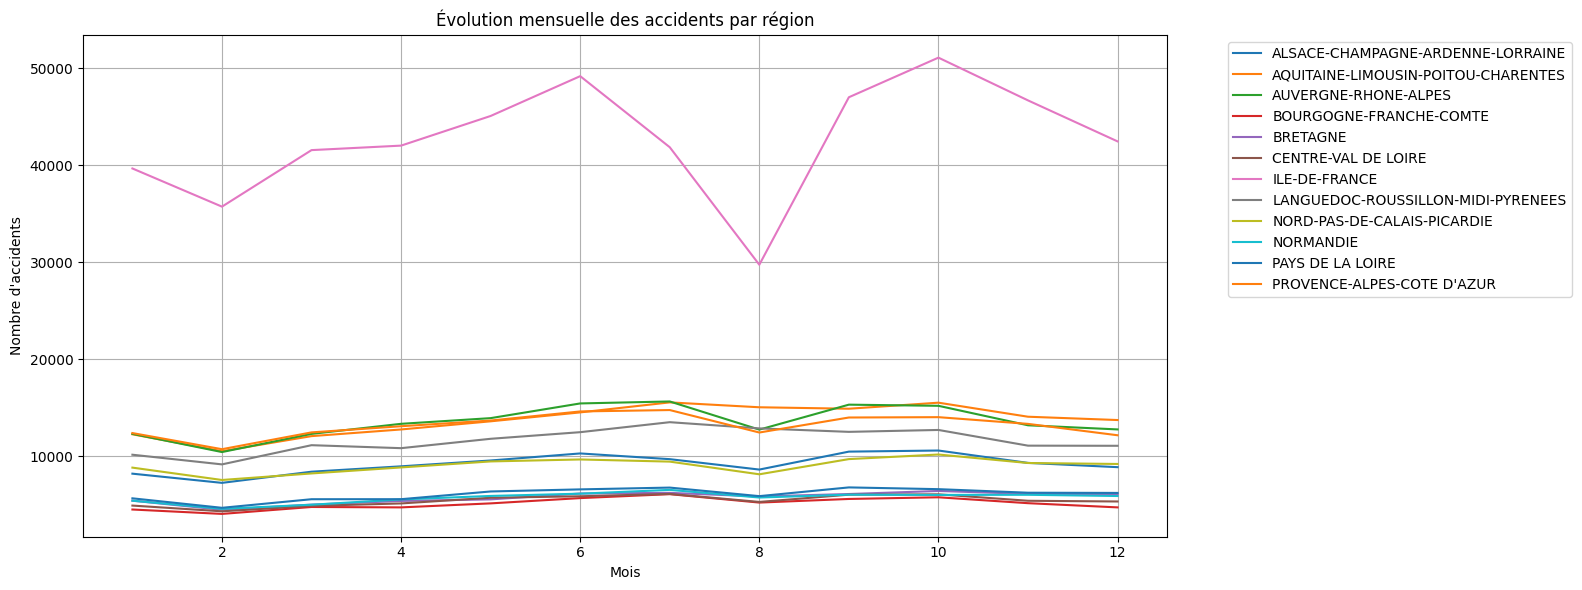

In [219]:
accidents_region_mois = THE_def.groupby(['NCC_y', 'Mois']).size().unstack(fill_value=0)
accidents_region_mois.T.plot(figsize=(16,6))
plt.title("Évolution mensuelle des accidents par région")
plt.xlabel("Mois")
plt.ylabel("Nombre d'accidents")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

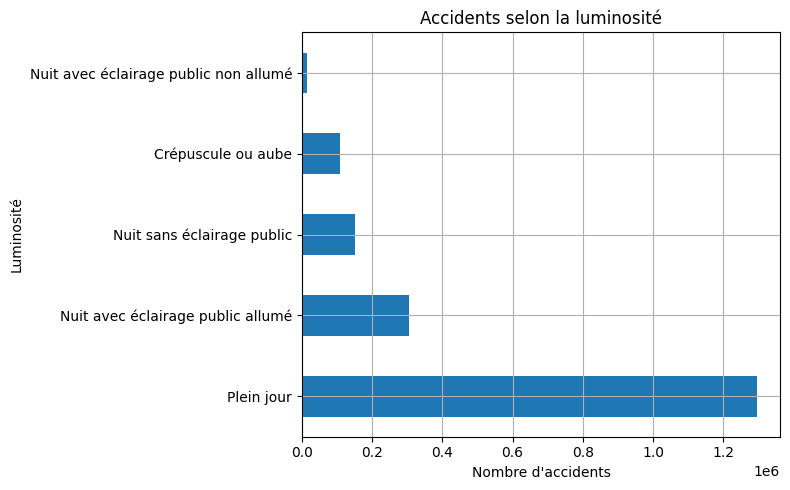

In [220]:
lum_counts = THE_df['Luminosité'].value_counts().sort_values(ascending=False)

lum_counts.plot(kind='barh', figsize=(8,5), title="Accidents selon la luminosité")
plt.xlabel("Nombre d'accidents")
plt.ylabel("Luminosité")
plt.grid(True)
plt.tight_layout()
plt.show()

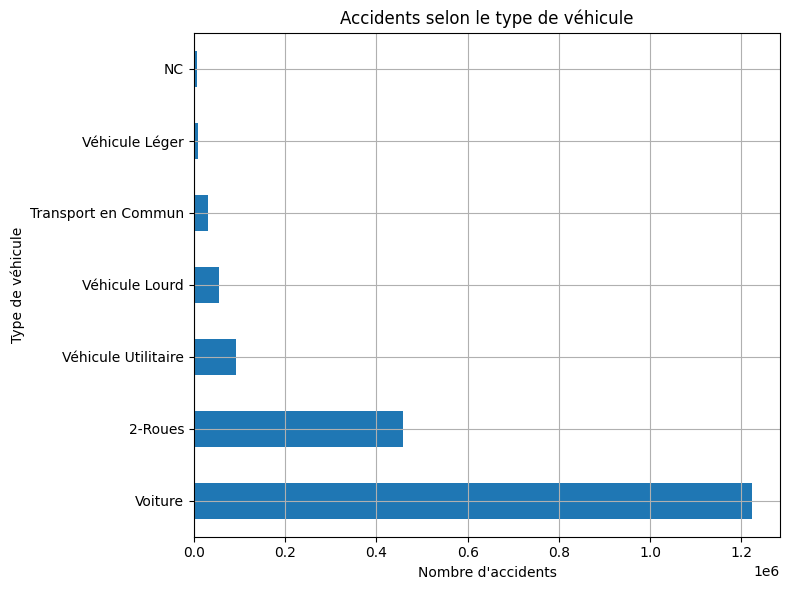

In [221]:
veh_counts = THE_df['Catégorie_x'].value_counts().sort_values(ascending=False)

veh_counts.plot(kind='barh', figsize=(8,6), title="Accidents selon le type de véhicule")
plt.xlabel("Nombre d'accidents")
plt.ylabel("Type de véhicule")
plt.tight_layout()
plt.grid(True)
plt.show()

In [226]:
THE_df.groupby(['Sexe_x', 'Age']).size()

Sexe_x  Age  
Femme   0.0      1139
        1.0      1839
        2.0      1899
        3.0      2305
        4.0      2292
                 ... 
Homme   105.0      22
        106.0      27
        107.0      51
        108.0      20
        109.0      46
Length: 219, dtype: int64